## Netflix Dataset Analysis**
## Author: Bammidi Anil
## Date: 2025-11-22
## Final Project 


## **Introduction**
This notebook performs comprehensive Exploratory Data Analysis (EDA), hypothesis testing, traditional statistical modeling, machine learning classification, and clustering on the Netflix Titles dataset from Kaggle. Commentary is provided throughout to explain each step.


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style='whitegrid')

# Load dataset (adjust path if needed on your machine)
df = pd.read_csv('netflix_titles.csv')

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## **Data Cleaning & Feature Engineering**
We extract numeric duration for movies and an approximate number of seasons for TV shows, parse the date added, and create a simple genre-count feature.


In [6]:
# Extract numeric duration and type (minutes vs seasons)
df['duration_type'] = df['duration'].str.extract(r'(\D+)$')[0].str.strip()
df['duration_value'] = df['duration'].str.extract(r'(\d+)').astype(float)

df['duration_minutes'] = np.where(
    df['duration_type'].str.contains('min', na=False),
    df['duration_value'],
    np.nan
)

df['seasons'] = np.where(
    df['duration_type'].str.contains('Season', na=False),
    df['duration_value'],
    np.nan
)

# Parse date_added and create year_added
df['date_added_parsed'] = pd.to_datetime(df['date_added'], errors='coerce')
df['year_added'] = df['date_added_parsed'].dt.year

# Number of genres
df['num_genres'] = df['listed_in'].fillna('').apply(
    lambda x: len(x.split(',')) if x.strip() else 0
)

df[['type', 'release_year', 'duration', 'duration_minutes', 'seasons', 'year_added', 'num_genres']].head()

,type,release_year,duration,duration_minutes,seasons,year_added,num_genres
0,Movie,2020,90 min,90.0,NaN,2021.0,1
1,TV Show,2021,2 Seasons,NaN,2.0,2021.0,3
2,TV Show,2021,1 Season,NaN,1.0,2021.0,3
3,TV Show,2021,1 Season,NaN,1.0,2021.0,2
4,TV Show,2021,2 Seasons,NaN,2.0,2021.0,3


## **Descriptive Statistics**
We compute mean, median, mode, variance, skewness, and kurtosis for key continuous variables to better understand their distributions.


In [7]:
cont_cols = ['release_year', 'year_added']

for col in cont_cols:
    print(f"--- {col} ---")
    print('Count:', df[col].count())
    print('Mean:', df[col].mean())
    print('Median:', df[col].median())
    print('Mode:', df[col].mode().iloc[0])
    print('Variance:', df[col].var())
    print('Standard Deviation:', df[col].std())
    print('Skewness:', df[col].skew())
    print('Kurtosis:', df[col].kurt())
    print()

--- release_year ---
Count: 8807
Mean: 2014.1801975701146
Median: 2017.0
Mode: 2018
Variance: 77.78026646107516
Standard Deviation: 8.819312130833966
Skewness: -3.4465650403316013
Kurtosis: 16.232225648417085

--- year_added ---
Count: 8797
Mean: 2018.8718881436853
Median: 2019.0
Mode: 2019.0
Variance: 2.4782421484690063
Standard Deviation: 1.574243357447954
Skewness: -0.7046795757260429
Kurtosis: 1.3197137589403347



## **Univariate Visualizations**
We inspect the distributions of `release_year` and `year_added` using histograms with density curves.


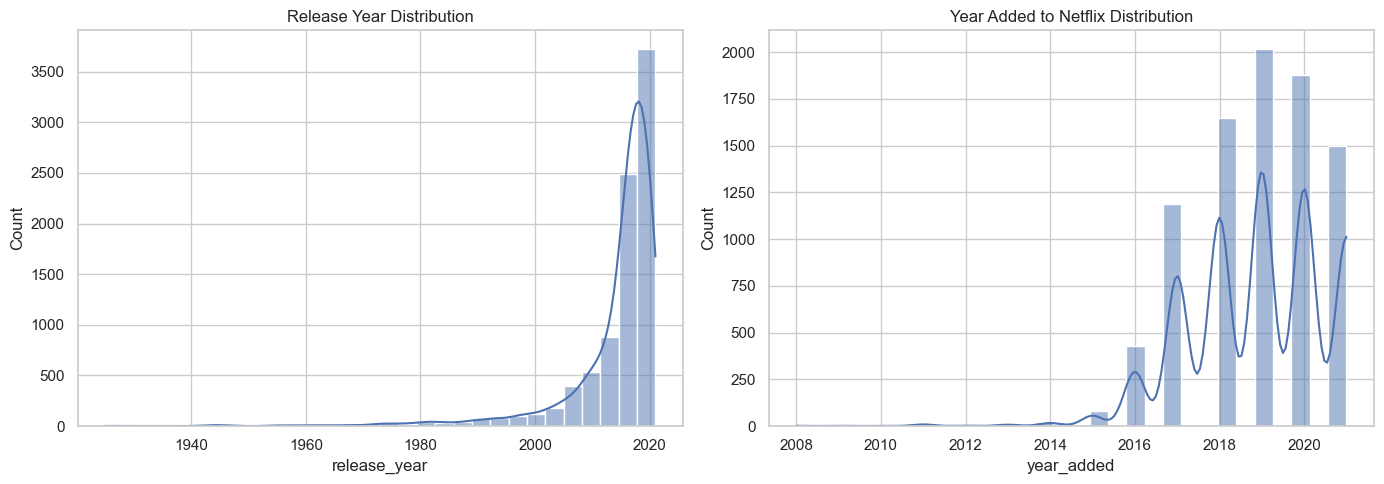

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['release_year'], kde=True, bins=30, ax=axes[0])
axes[0].set_title('Release Year Distribution')

sns.histplot(df['year_added'], kde=True, bins=30, ax=axes[1])
axes[1].set_title('Year Added to Netflix Distribution')

plt.tight_layout()
plt.show()

## **Categorical vs Continuous Relationships**
Here we examine how continuous variables (such as duration) are distributed across different categories (such as type and rating).

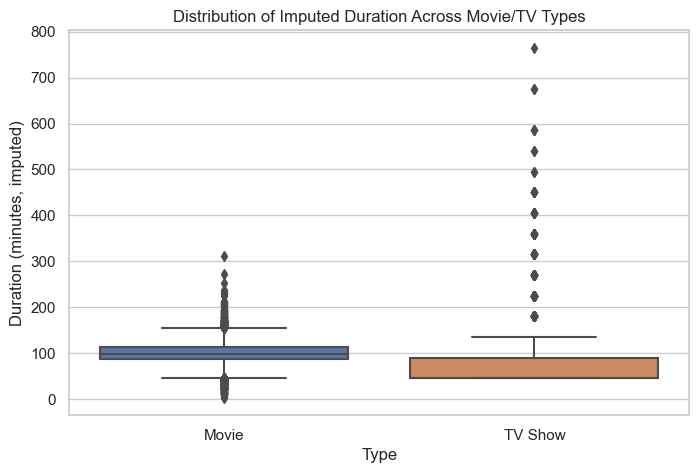

In [9]:
# Impute approximate duration in minutes for TV shows if not already done
if 'duration_minutes_imputed' not in df.columns:
    df['duration_minutes_imputed'] = df['duration_minutes']
    tv_mask = (df['type'] == 'TV Show') & df['seasons'].notna()
    df.loc[tv_mask, 'duration_minutes_imputed'] = df.loc[tv_mask, 'seasons'] * 45  # rough approximation

# Boxplot: Duration vs Type (Movie vs TV Show)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='type', y='duration_minutes_imputed')
plt.title('Distribution of Imputed Duration Across Movie/TV Types')
plt.xlabel('Type')
plt.ylabel('Duration (minutes, imputed)')
plt.show()

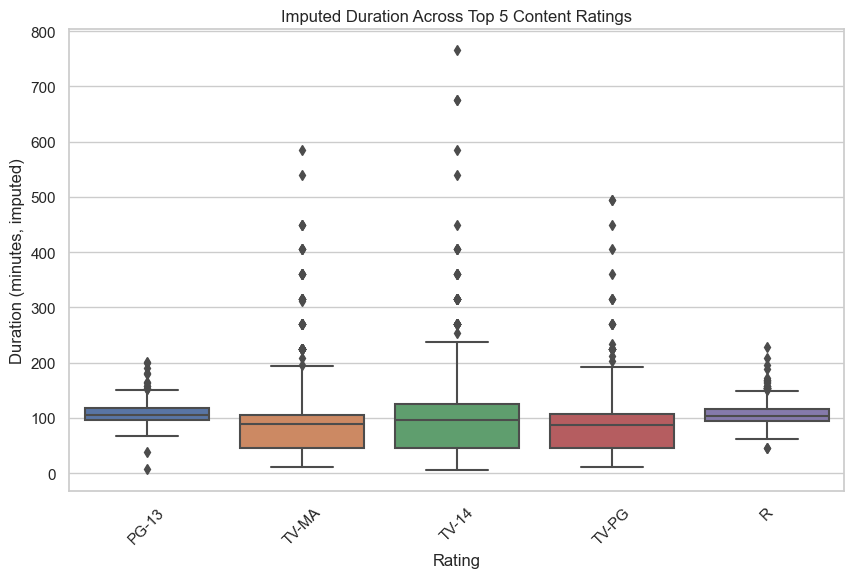

In [10]:
# Boxplot: Duration vs Rating (Top 5 Ratings)
top_ratings = df['rating'].value_counts().head(5).index
subset = df[df['rating'].isin(top_ratings)].copy()

plt.figure(figsize=(10, 6))
sns.boxplot(data=subset, x='rating', y='duration_minutes_imputed')
plt.title('Imputed Duration Across Top 5 Content Ratings')
plt.xlabel('Rating')
plt.ylabel('Duration (minutes, imputed)')
plt.xticks(rotation=45)
plt.show()

## **Bivariate Analysis & Correlation**
We explore relationships between continuous variables using a correlation matrix.


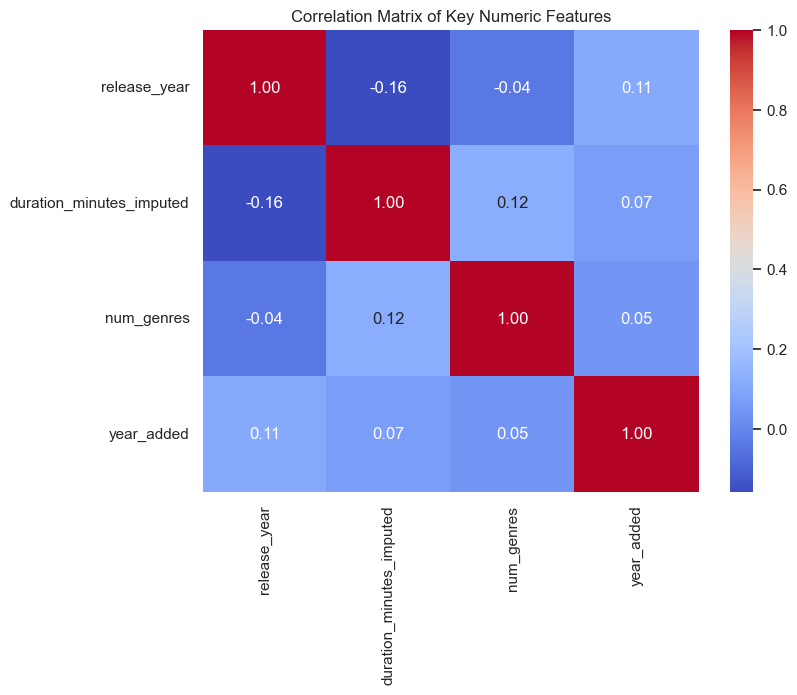

In [11]:
corr_df = df[['release_year', 'duration_minutes_imputed', 'num_genres', 'year_added']].dropna()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Key Numeric Features')
plt.show()

## **Hypothesis Testing – Chi-square (Type vs Rating)**
We test whether show type (Movie vs TV Show) is independent of content rating.


In [12]:
ct = pd.crosstab(df['type'], df['rating'])
chi2, p, dof, expected = stats.chi2_contingency(ct)

print('Chi-square statistic:', chi2)
print('Degrees of freedom:', dof)
print('p-value:', p)

Chi-square statistic: 1047.6941440561634
Degrees of freedom: 16
p-value: 6.822436324208583e-213


## **Traditional Classification – Logistic Regression**
We build a logistic regression model to predict whether a title is a Movie or TV Show based on numeric metadata.


In [13]:
# Ensure duration_minutes_imputed exists
if 'duration_minutes_imputed' not in df.columns:
    df['duration_minutes_imputed'] = df['duration_minutes']
    tv_mask = (df['type'] == 'TV Show') & df['seasons'].notna()
    df.loc[tv_mask, 'duration_minutes_imputed'] = df.loc[tv_mask, 'seasons'] * 45

# Build classification dataset
clf = df[['type', 'release_year', 'duration_minutes_imputed', 'num_genres', 'year_added']].dropna()
clf['type_binary'] = (clf['type'] == 'Movie').astype(int)

X = clf[['release_year', 'duration_minutes_imputed', 'num_genres', 'year_added']]
y = clf['type_binary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

# Scale features for logistic regression
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_s, y_train)
pred_lr = lr.predict(X_test_s)

print("Logistic Regression Classification Report:\n")
print(classification_report(y_test, pred_lr))

print("Confusion Matrix:\n", confusion_matrix(y_test, pred_lr))

Logistic Regression Classification Report:

              precision    recall  f1-score   support

           0       0.90      0.31      0.46       800
           1       0.77      0.99      0.86      1839

    accuracy                           0.78      2639
   macro avg       0.83      0.65      0.66      2639
weighted avg       0.81      0.78      0.74      2639

Confusion Matrix:
 [[ 246  554]
 [  27 1812]]


## **Machine Learning – Random Forest with Cross-validation**
We train a Random Forest classifier on the same features and use cross-validation to estimate its performance.


In [14]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
cv_scores = cross_val_score(rf, X, y, cv=5, scoring='accuracy')

print('Cross-validated accuracy scores:', cv_scores)
print('Mean CV accuracy:', cv_scores.mean())

Cross-validated accuracy scores: [0.95679363 0.95622513 0.89482661 0.95736214 0.95108077]
Mean CV accuracy: 0.9432576555740315


## **Clustering Analysis – KMeans + PCA Visualization**
We cluster titles using KMeans on numeric features and visualize the clusters in 2D with PCA.


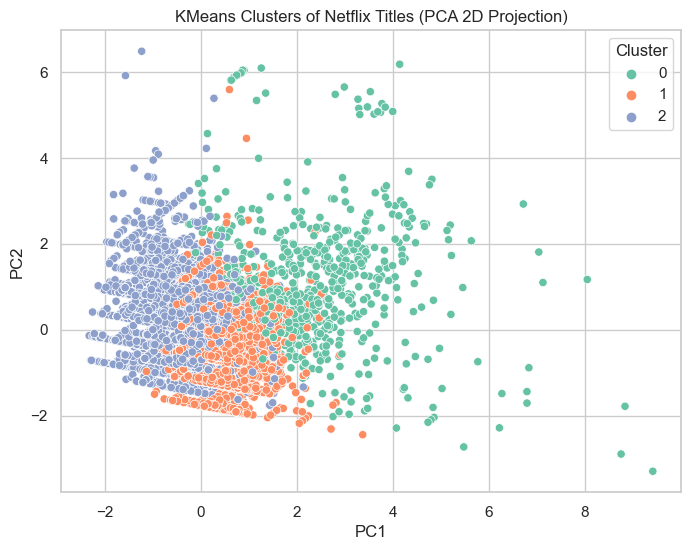

In [15]:
cluster_df = clf[['release_year', 'duration_minutes_imputed', 'num_genres', 'year_added']]
scaled_cluster = StandardScaler().fit_transform(cluster_df)

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = kmeans.fit_predict(scaled_cluster)

pca = PCA(n_components=2)
coords = pca.fit_transform(scaled_cluster)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=labels, palette='Set2')
plt.title('KMeans Clusters of Netflix Titles (PCA 2D Projection)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Cluster')
plt.show()